In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append("..")  # Adjust the path to include the parent directory

import torch
from thermo.models import simple

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 12
cmap = "coolwarm"

In [2]:
path = "../.dataset/train.csv" # change this to path to dataset 
df = pd.read_csv(path, header=[0, 1])

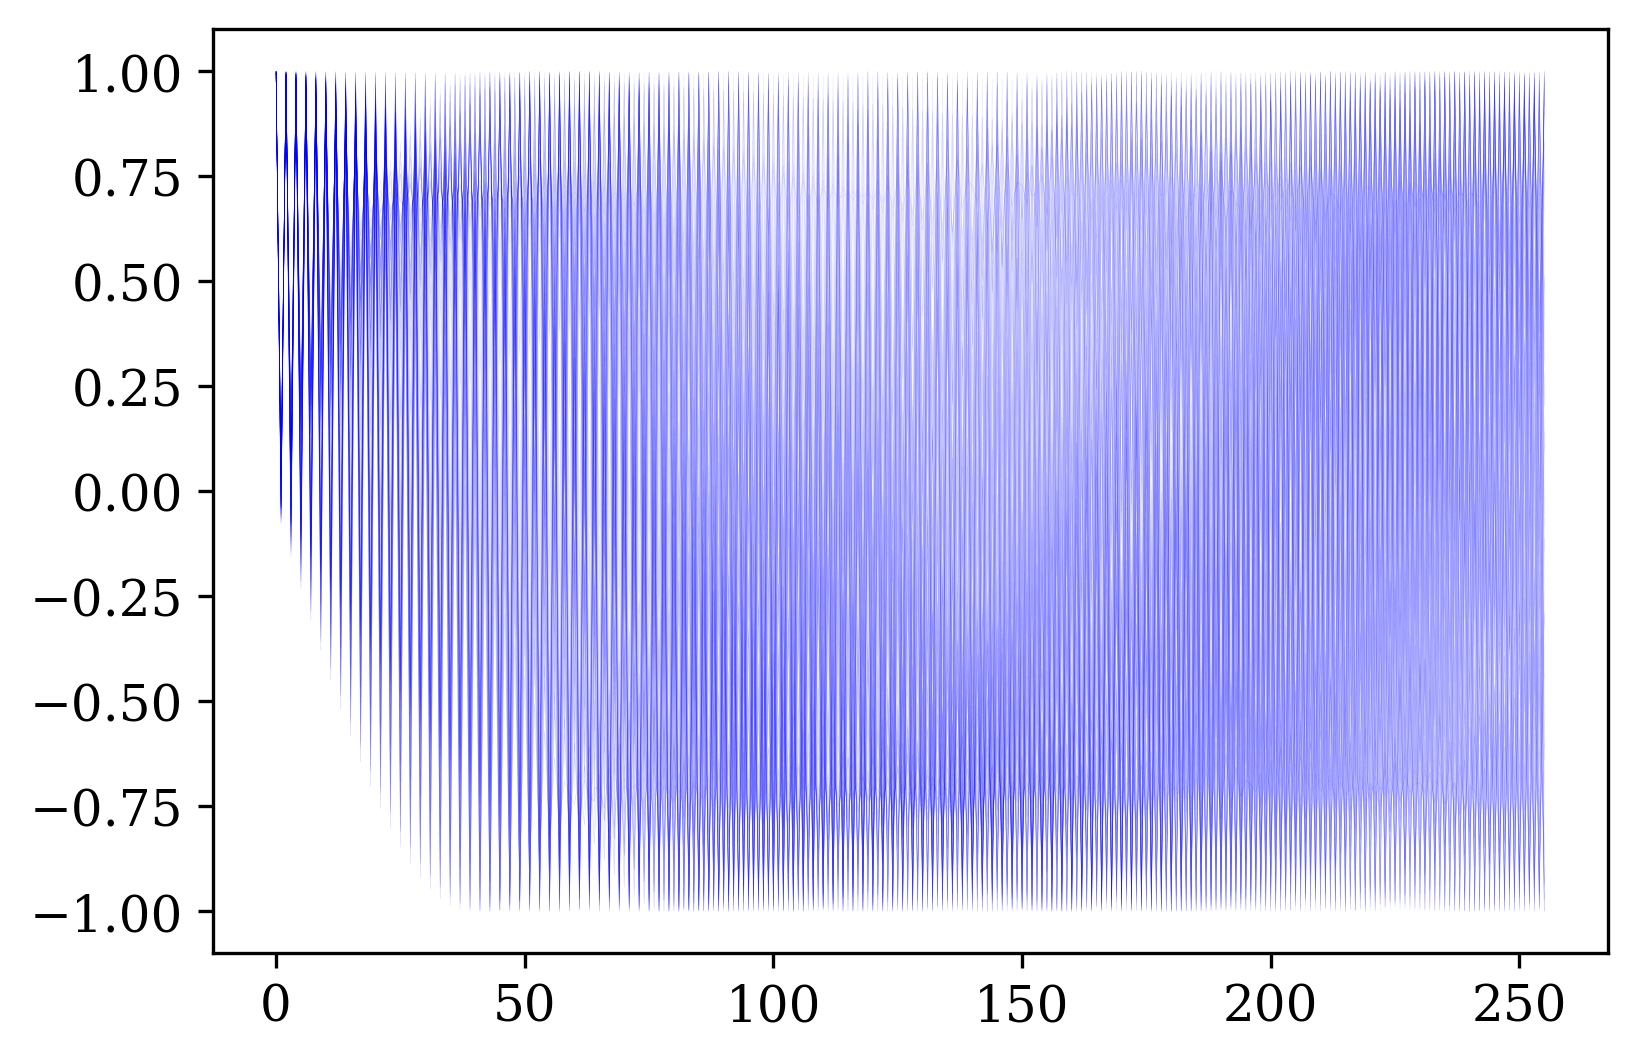

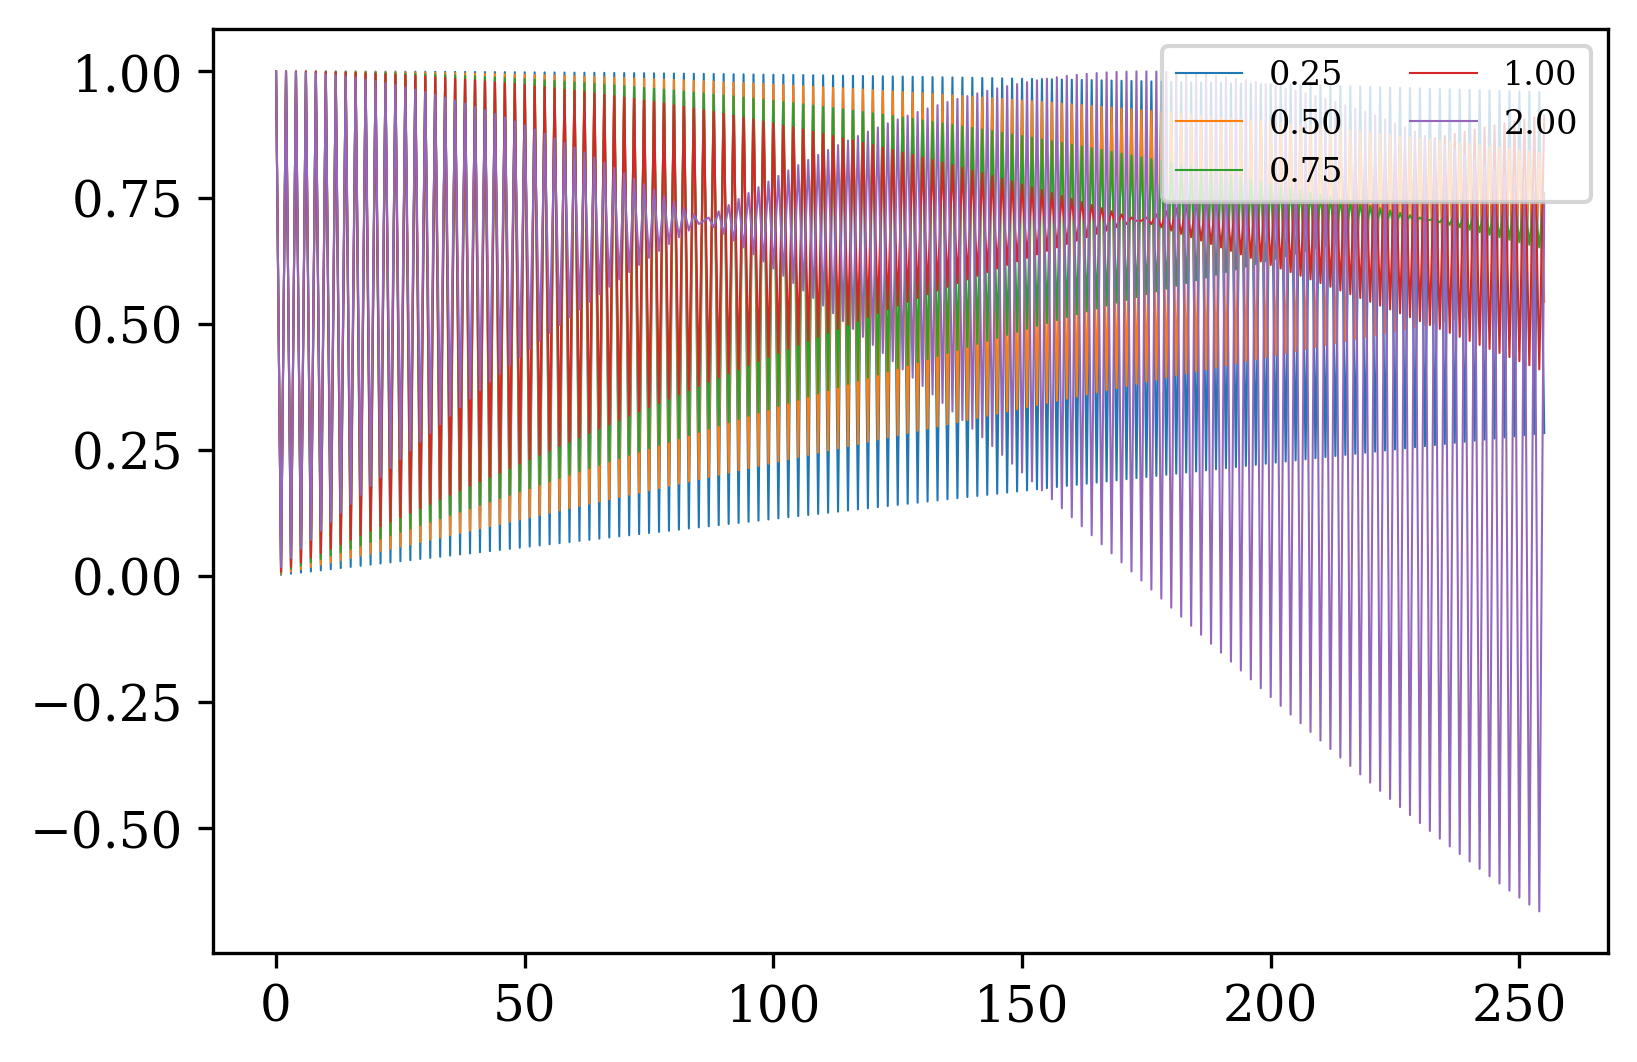

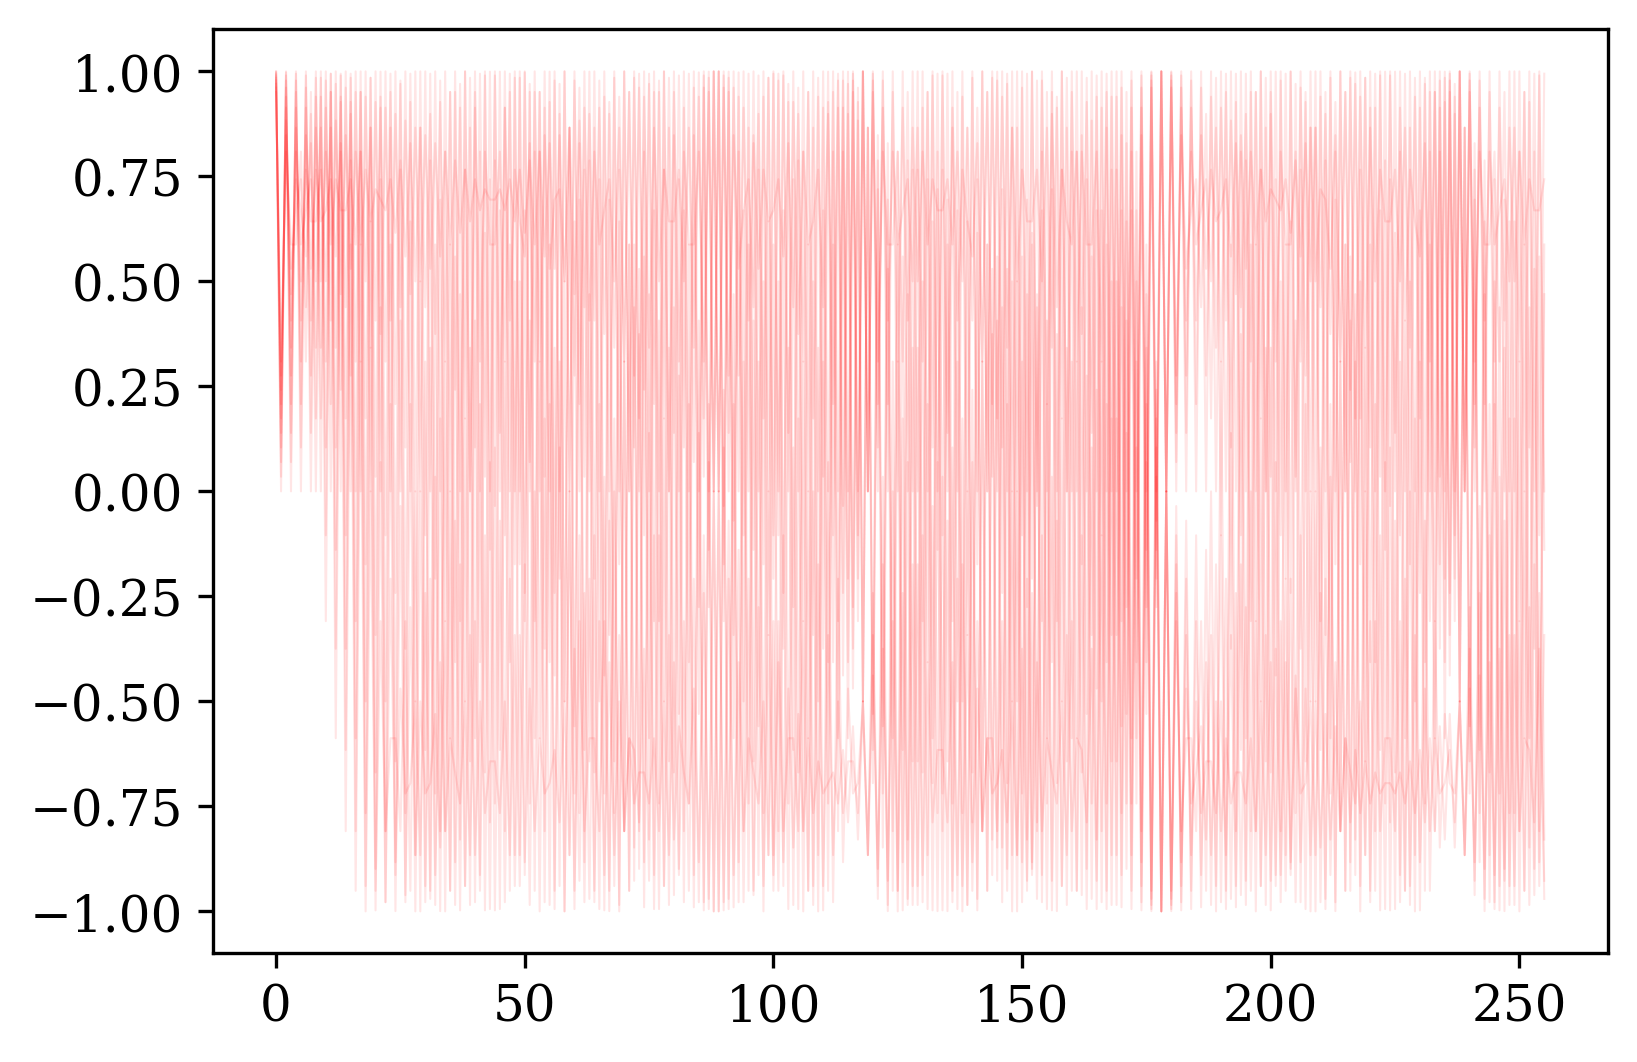

In [3]:
beta = 1.0

x = df[f"{beta:.2f}"]["x"].values[:100]
x = torch.tensor(x, dtype=torch.float32).unsqueeze(1)
y = df[f"{beta:.2f}"]["y"].values[:100]
y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

pos_enc = simple.PositionalEncoder(256, max_length=50)
enc_x = pos_enc(x).squeeze().T

pos_enc = simple.PositionalEncoder(256, max_length=50)
enc_theta = pos_enc(y).squeeze().T


fig, ax = plt.subplots(figsize=(6, 4), dpi=300)
ax.plot(enc_theta, alpha=0.1, c="b", linewidth=0.1)
plt.show()

betas = [0.25, 0.5, 0.75, 1.0, 2.0]
pos_enc = simple.PositionalEncoder(256, max_length=350)
beta_enc = pos_enc(torch.tensor(betas, dtype=torch.float32).unsqueeze(1)).squeeze().T

fig, ax = plt.subplots(figsize=(6, 4), dpi=300)
ax.plot(beta_enc, linewidth=0.5)

labels = [f"{beta:.2f}" for beta in betas]
ax.legend(labels, loc='upper right', fontsize=8, ncol=2)
plt.show()

times = np.linspace(0, 1, 10)
pos_enc = simple.PositionalEncoder(256, max_length=10)
time_enc = pos_enc(torch.tensor(times, dtype=torch.float32).unsqueeze(1)).squeeze().T
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)
ax.plot(time_enc, linewidth=0.5, c="r", alpha=0.1)

plt.show()
